# ML Lab Assignment 3

## HMM, CNN and Deep Learning Models

Rahul Pandey

Roll Number: 002311001021

Colab Notebook Link: https://colab.research.google.com/drive/1ekBNZSGUDg4_V3JLNdxw5Wy60BjViZJG?usp=sharing

In [ ]:
!pip install hmmlearn
!pip install ucimlrepo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 6.1 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from hmmlearn import hmm
from ucimlrepo import fetch_ucirepo
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                              precision_recall_fscore_support, roc_curve, auc)
from sklearn.preprocessing import MinMaxScaler, label_binarize
import tensorflow as tf
from tensorflow.keras import datasets, models, layers

## Q1. HMM Classification

In [ ]:
def load_ionosphere():
    data = fetch_ucirepo(id=52)
    X = data.data.features.values.astype(float)
    y = data.data.targets.values.ravel()
    y = np.where(y == "g", 1, 0)
    return X, y

def load_breast_cancer_data():
    bc = load_breast_cancer()
    return bc.data, bc.target

DATASETS = {
    "Ionosphere": load_ionosphere(),
    "Breast Cancer Wisconsin": load_breast_cancer_data(),
}

In [ ]:
def discretize(X_train, X_test, n_bins=10):
    scaler = MinMaxScaler(feature_range=(0, n_bins - 1))
    X_train_d = np.clip(scaler.fit_transform(X_train).astype(int), 0, n_bins - 1)
    X_test_d = np.clip(scaler.transform(X_test).astype(int), 0, n_bins - 1)
    return X_train_d, X_test_d

def make_hmm(model_type, n_components, covariance_type="diag", n_iter=200):
    if model_type == "Gaussian":
        return hmm.GaussianHMM(n_components=n_components, covariance_type=covariance_type,
                                n_iter=n_iter, random_state=42)
    return hmm.MultinomialHMM(n_components=n_components, n_iter=n_iter, random_state=42)

def fit_class_hmms(X_train, y_train, model_type, **hmm_kwargs):
    return {c: make_hmm(model_type, **hmm_kwargs).fit(X_train[y_train == c]) for c in np.unique(y_train)}

def hmm_class_scores(models_by_class, X):
    classes = sorted(models_by_class.keys())
    scores = np.full((len(X), len(classes)), -np.inf)
    for j, c in enumerate(classes):
        for i in range(len(X)):
            try:
                scores[i, j] = models_by_class[c].score(X[i:i + 1])
            except Exception:
                pass
    return scores, classes

def hmm_predict(models_by_class, X):
    scores, classes = hmm_class_scores(models_by_class, X)
    return np.array([classes[i] for i in np.argmax(scores, axis=1)]), scores

In [ ]:
HMM_PARAM_GRID = {
    "Gaussian": [{"n_components": nc, "covariance_type": ct} for nc in (2, 3, 4) for ct in ("diag", "full")],
    "Multinomial": [{"n_components": nc} for nc in (2, 3, 4)],
}

def run_hmm_classifier(dataset_name, X, y, model_type, splits=(0.2, 0.3, 0.4, 0.5), tune=False, n_bins=10):
    best = None
    param_list = HMM_PARAM_GRID[model_type] if tune else HMM_PARAM_GRID[model_type][:1]
    for split in splits:
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=split, random_state=42, stratify=y)
        if model_type == "Multinomial":
            X_train, X_test = discretize(X_train, X_test, n_bins)
        for params in param_list:
            try:
                models_by_class = fit_class_hmms(X_train, y_train, model_type, n_iter=200, **params)
                y_pred, scores = hmm_predict(models_by_class, X_test)
            except Exception:
                continue
            acc = accuracy_score(y_test, y_pred)
            prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="weighted", zero_division=0)
            result = {"dataset": dataset_name, "model_type": model_type, "tuned": tune, "split": split,
                      "params": params, "accuracy": acc, "precision": prec, "recall": rec, "f1": f1,
                      "y_test": y_test, "y_pred": y_pred, "scores": scores, "models": models_by_class}
            if best is None or acc > best["accuracy"]:
                best = result
    return best

In [ ]:
def plot_confusion_heatmap(cm, classes, title, fname):
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(title)
    plt.tight_layout(); plt.savefig(fname); plt.show()

def plot_hmm_training_curve(history, title, fname):
    plt.figure(figsize=(5, 4))
    plt.plot(history)
    plt.xlabel("Iteration"); plt.ylabel("Log-likelihood"); plt.title(title)
    plt.tight_layout(); plt.savefig(fname); plt.show()

def plot_roc(fpr, tpr, roc_auc, title, fname):
    plt.figure(figsize=(5, 5))
    for k in fpr:
        plt.plot(fpr[k], tpr[k], label=f"class {k} (AUC={roc_auc[k]:.2f})")
    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title(title); plt.legend()
    plt.tight_layout(); plt.savefig(fname); plt.show()

In [ ]:
hmm_records, hmm_best = [], {}

for dataset_name, (X, y) in DATASETS.items():
    for model_type in ("Gaussian", "Multinomial"):
        for tune in (False, True):
            result = run_hmm_classifier(dataset_name, X, y, model_type, tune=tune)
            hmm_records.append({k: v for k, v in result.items() if k not in ("y_test", "y_pred", "scores", "models")})
            key = (dataset_name, model_type)
            if key not in hmm_best or result["accuracy"] > hmm_best[key]["accuracy"]:
                hmm_best[key] = result

hmm_comparison = pd.DataFrame(hmm_records)
hmm_comparison

https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/iss

,dataset,model_type,tuned,split,params,accuracy,precision,recall,f1
0,Ionosphere,Gaussian,False,0.2,"{'n_components': 2, 'covariance_type': 'diag'}",0.830986,0.871339,0.830986,0.834765
1,Ionosphere,Gaussian,True,0.2,"{'n_components': 2, 'covariance_type': 'full'}",0.929577,0.931106,0.929577,0.928442
2,Ionosphere,Multinomial,False,0.2,{'n_components': 2},0.732394,0.725048,0.732394,0.714946
3,Ionosphere,Multinomial,True,0.2,{'n_components': 2},0.732394,0.725048,0.732394,0.714946
4,Breast Cancer Wisconsin,Gaussian,False,0.3,"{'n_components': 2, 'covariance_type': 'diag'}",0.929825,0.936901,0.929825,0.928058
5,Breast Cancer Wisconsin,Gaussian,True,0.5,"{'n_components': 3, 'covariance_type': 'diag'}",0.940351,0.940488,0.940351,0.940407
6,Breast Cancer Wisconsin,Multinomial,False,0.2,{'n_components': 2},0.789474,0.808247,0.789474,0.792816
7,Breast Cancer Wisconsin,Multinomial,True,0.2,{'n_components': 2},0.789474,0.808247,0.789474,0.792816


## Output

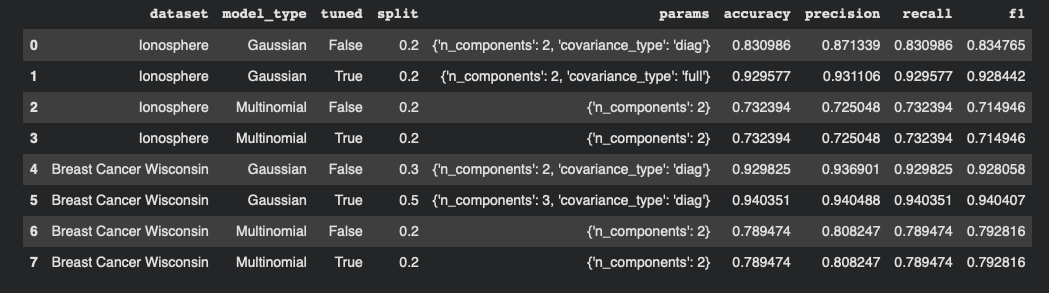


=== Ionosphere - GaussianHMM (best split=0.2, tuned=True, params={'n_components': 2, 'covariance_type': 'full'}) ===
              precision    recall  f1-score   support

           0       0.95      0.84      0.89        25
           1       0.92      0.98      0.95        46

    accuracy                           0.93        71
   macro avg       0.94      0.91      0.92        71
weighted avg       0.93      0.93      0.93        71



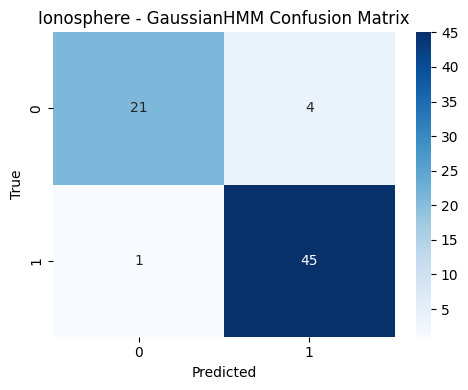

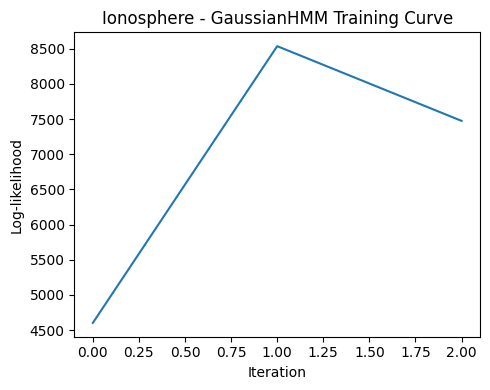

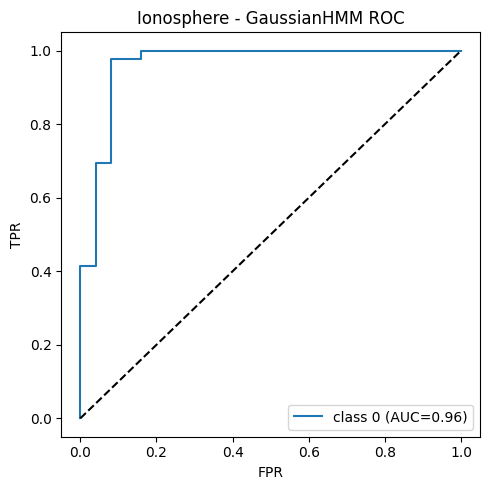


=== Ionosphere - MultinomialHMM (best split=0.2, tuned=False, params={'n_components': 2}) ===
              precision    recall  f1-score   support

           0       0.69      0.44      0.54        25
           1       0.75      0.89      0.81        46

    accuracy                           0.73        71
   macro avg       0.72      0.67      0.67        71
weighted avg       0.73      0.73      0.71        71



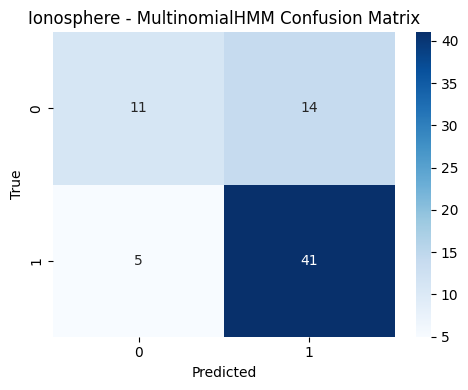

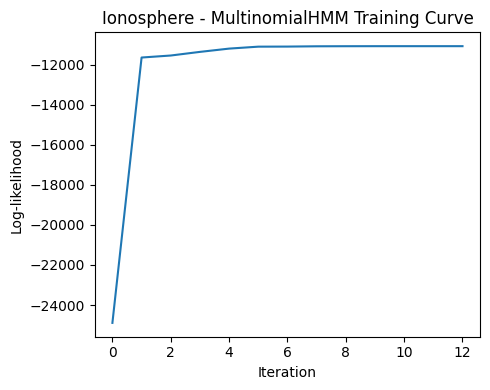

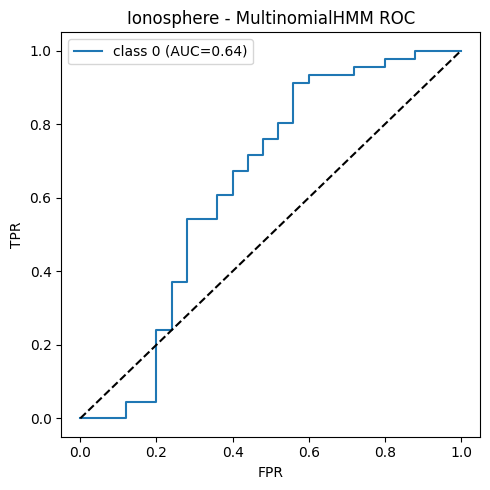


=== Breast Cancer Wisconsin - GaussianHMM (best split=0.5, tuned=True, params={'n_components': 3, 'covariance_type': 'diag'}) ===
              precision    recall  f1-score   support

           0       0.92      0.92      0.92       106
           1       0.96      0.95      0.95       179

    accuracy                           0.94       285
   macro avg       0.94      0.94      0.94       285
weighted avg       0.94      0.94      0.94       285



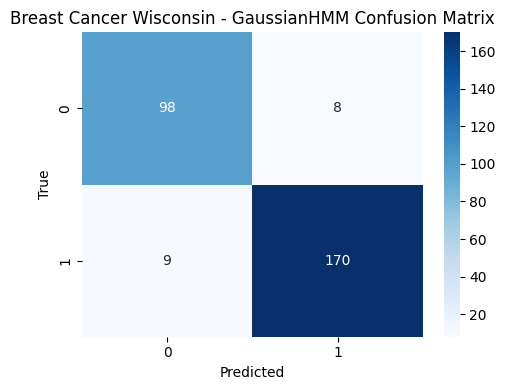

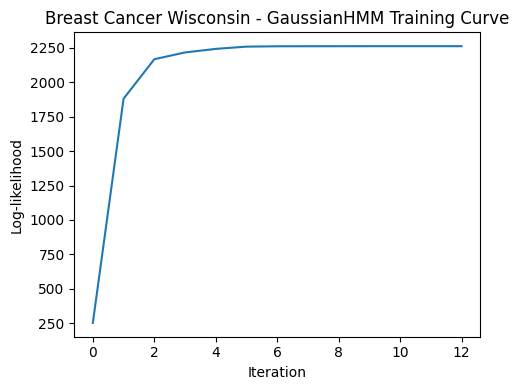

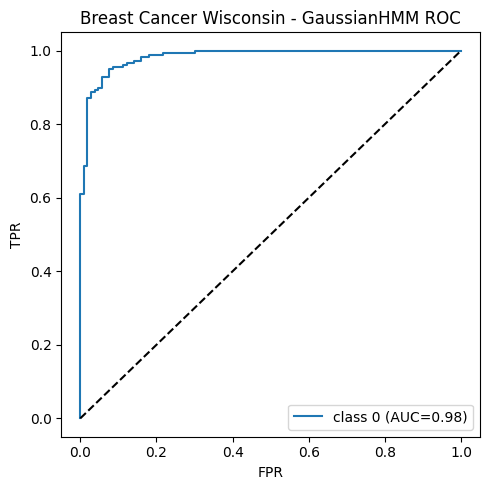


=== Breast Cancer Wisconsin - MultinomialHMM (best split=0.2, tuned=False, params={'n_components': 2}) ===
              precision    recall  f1-score   support

           0       0.67      0.83      0.74        42
           1       0.89      0.76      0.82        72

    accuracy                           0.79       114
   macro avg       0.78      0.80      0.78       114
weighted avg       0.81      0.79      0.79       114



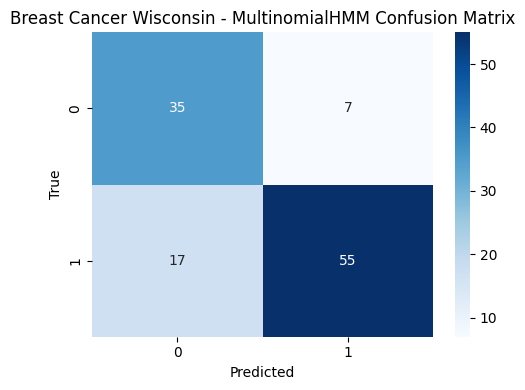

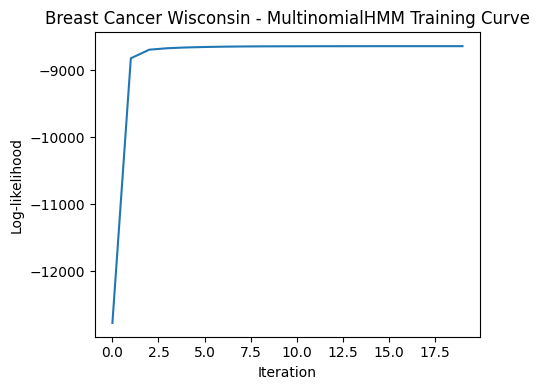

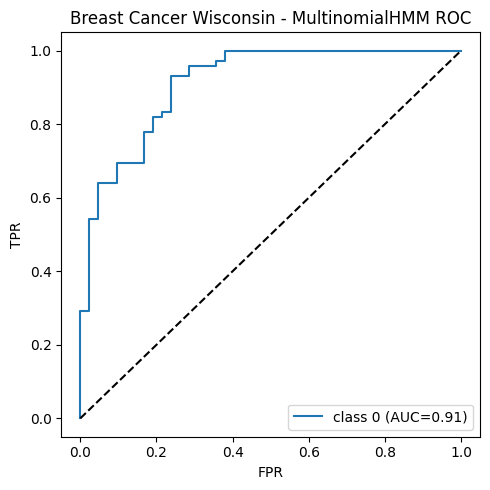

In [ ]:
for (dataset_name, model_type), best in hmm_best.items():
    print(f"\n=== {dataset_name} - {model_type}HMM (best split={best['split']}, tuned={best['tuned']}, params={best['params']}) ===")
    print(classification_report(best["y_test"], best["y_pred"]))

    cm = confusion_matrix(best["y_test"], best["y_pred"])
    classes = sorted(best["models"].keys())
    plot_confusion_heatmap(cm, classes, f"{dataset_name} - {model_type}HMM Confusion Matrix",
                            f"{dataset_name}_{model_type}_hmm_cm.png")

    top_class_model = best["models"][classes[-1]]
    if hasattr(top_class_model, "monitor_"):
        plot_hmm_training_curve(top_class_model.monitor_.history,
                                 f"{dataset_name} - {model_type}HMM Training Curve",
                                 f"{dataset_name}_{model_type}_hmm_train.png")

    score_diff = best["scores"][:, -1] - best["scores"][:, 0]
    fpr, tpr, _ = roc_curve(best["y_test"], score_diff)
    roc_auc = auc(fpr, tpr)
    plot_roc({0: fpr}, {0: tpr}, {0: roc_auc}, f"{dataset_name} - {model_type}HMM ROC",
              f"{dataset_name}_{model_type}_hmm_roc.png")

## Q2 & 3: CNN and other Deep Learning models

In [ ]:
def preprocess_images(images, size=(32, 32)):
    images = images.astype("float32") / 255.0
    if images.ndim == 3:
        images = np.expand_dims(images, -1)
    images = tf.image.resize(images, size).numpy()
    if images.shape[-1] == 1:
        images = np.repeat(images, 3, axis=-1)
    return images

def load_mnist():
    (xtr, ytr), (xte, yte) = datasets.mnist.load_data()
    return preprocess_images(np.concatenate([xtr, xte])), np.concatenate([ytr, yte])

def load_cifar10():
    (xtr, ytr), (xte, yte) = datasets.cifar10.load_data()
    return preprocess_images(np.concatenate([xtr, xte])), np.concatenate([ytr, yte]).ravel()

IMAGE_DATASETS = {"MNIST": load_mnist(), "CIFAR-10": load_cifar10()}

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 247s 1us/step


In [ ]:
def build_cnn(input_shape, num_classes):
    return models.Sequential([
        layers.Conv2D(32, 3, activation="relu", input_shape=input_shape),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(num_classes),
    ])

def build_vgg16(input_shape, num_classes):
    inp = layers.Input(shape=input_shape)
    x = inp
    for filters in (64, 128, 256, 512, 512):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D(padding="same")(x)
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dense(256, activation="relu")(x)
    out = layers.Dense(num_classes)(x)
    return models.Model(inp, out)

def build_alexnet(input_shape, num_classes):
    inp = layers.Input(shape=input_shape)
    x = layers.Conv2D(96, 5, padding="same", activation="relu")(inp)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(256, 5, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(384, 3, padding="same", activation="relu")(x)
    x = layers.Conv2D(384, 3, padding="same", activation="relu")(x)
    x = layers.Conv2D(256, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(1024, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(1024, activation="relu")(x)
    out = layers.Dense(num_classes)(x)
    return models.Model(inp, out)

def inception_module(x, f1, f3r, f3, f5r, f5, fpp):
    b1 = layers.Conv2D(f1, 1, padding="same", activation="relu")(x)
    b2 = layers.Conv2D(f3r, 1, padding="same", activation="relu")(x)
    b2 = layers.Conv2D(f3, 3, padding="same", activation="relu")(b2)
    b3 = layers.Conv2D(f5r, 1, padding="same", activation="relu")(x)
    b3 = layers.Conv2D(f5, 5, padding="same", activation="relu")(b3)
    b4 = layers.MaxPooling2D(3, strides=1, padding="same")(x)
    b4 = layers.Conv2D(fpp, 1, padding="same", activation="relu")(b4)
    return layers.Concatenate()([b1, b2, b3, b4])

def build_googlenet(input_shape, num_classes):
    inp = layers.Input(shape=input_shape)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(inp)
    x = layers.MaxPooling2D()(x)
    x = inception_module(x, 64, 96, 128, 16, 32, 32)
    x = inception_module(x, 128, 128, 192, 32, 96, 64)
    x = layers.MaxPooling2D()(x)
    x = inception_module(x, 192, 96, 208, 16, 48, 64)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(num_classes)(x)
    return models.Model(inp, out)

def build_rnn(input_shape, num_classes):
    h, w, c = input_shape
    inp = layers.Input(shape=input_shape)
    x = layers.Reshape((h, w * c))(inp)
    x = layers.LSTM(128, return_sequences=True)(x)
    x = layers.LSTM(64)(x)
    x = layers.Dense(64, activation="relu")(x)
    out = layers.Dense(num_classes)(x)
    return models.Model(inp, out)

MODEL_BUILDERS = {
    "CNN": build_cnn,
    "VGG-16": build_vgg16,
    "AlexNet": build_alexnet,
    "GoogLeNet": build_googlenet,
    "RNN": build_rnn,
}

In [ ]:
def plot_training_curves(history, title, fname):
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].plot(history["accuracy"], label="train"); ax[0].plot(history["val_accuracy"], label="val")
    ax[0].set_title(f"{title} - Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(history["loss"], label="train"); ax[1].plot(history["val_loss"], label="val")
    ax[1].set_title(f"{title} - Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    plt.tight_layout(); plt.savefig(fname); plt.show()

def train_and_evaluate(name, model_fn, X_train, y_train, X_test, y_test, num_classes, epochs=5):
    model = model_fn(X_train.shape[1:], num_classes)
    model.compile(optimizer="adam",
                  loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                  metrics=["accuracy"])
    history = model.fit(X_train, y_train, epochs=epochs, validation_data=(X_test, y_test), verbose=0)

    probs = tf.nn.softmax(model.predict(X_test, verbose=0)).numpy()
    y_pred = np.argmax(probs, axis=1)

    acc = accuracy_score(y_test, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="weighted", zero_division=0)
    cm = confusion_matrix(y_test, y_pred)

    y_bin = label_binarize(y_test, classes=list(range(num_classes)))
    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(num_classes):
        fpr[i], tpr[i], _ = roc_curve(y_bin[:, i], probs[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    return {"name": name, "history": history.history, "accuracy": acc, "precision": prec,
            "recall": rec, "f1": f1, "confusion_matrix": cm, "fpr": fpr, "tpr": tpr,
            "roc_auc": roc_auc, "macro_auc": float(np.mean(list(roc_auc.values())))}

In [ ]:
dl_splits = [0.2, 0.3]
dl_records, dl_best = [], {}

for dataset_name, (X, y) in IMAGE_DATASETS.items():
    num_classes = len(np.unique(y))
    for split in dl_splits:
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=split, random_state=42, stratify=y)
        for model_name, model_fn in MODEL_BUILDERS.items():
            result = train_and_evaluate(model_name, model_fn, X_train, y_train, X_test, y_test, num_classes)
            record = {"dataset": dataset_name, "model": model_name, "split": split,
                      "accuracy": result["accuracy"], "precision": result["precision"],
                      "recall": result["recall"], "f1": result["f1"], "macro_auc": result["macro_auc"]}
            dl_records.append(record)
            key = (dataset_name, model_name)
            if key not in dl_best or result["accuracy"] > dl_best[key]["accuracy"]:
                dl_best[key] = {**result, "split": split, "num_classes": num_classes}

dl_comparison = pd.DataFrame(dl_records)
dl_comparison

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regulariz

,dataset,model,split,accuracy,precision,recall,f1,macro_auc
0,MNIST,CNN,0.2,0.987714,0.987811,0.987714,0.987723,0.999900
1,MNIST,VGG-16,0.2,0.987214,0.987322,0.987214,0.987223,0.999604
2,MNIST,AlexNet,0.2,0.988000,0.988091,0.988000,0.988006,0.999832
3,MNIST,GoogLeNet,0.2,0.992643,0.992664,0.992643,0.992643,0.999957
4,MNIST,RNN,0.2,0.985214,0.985312,0.985214,0.985218,0.999742
5,MNIST,CNN,0.3,0.988905,0.989039,0.988905,0.988925,0.999889
6,MNIST,VGG-16,0.3,0.112524,0.012662,0.112524,0.022762,0.500000
7,MNIST,AlexNet,0.3,0.986667,0.986758,0.986667,0.986679,0.999740
8,MNIST,GoogLeNet,0.3,0.989762,0.989864,0.989762,0.989764,0.999903
9,MNIST,RNN,0.3,0.981762,0.982113,0.981762,0.981777,0.999591


## Output

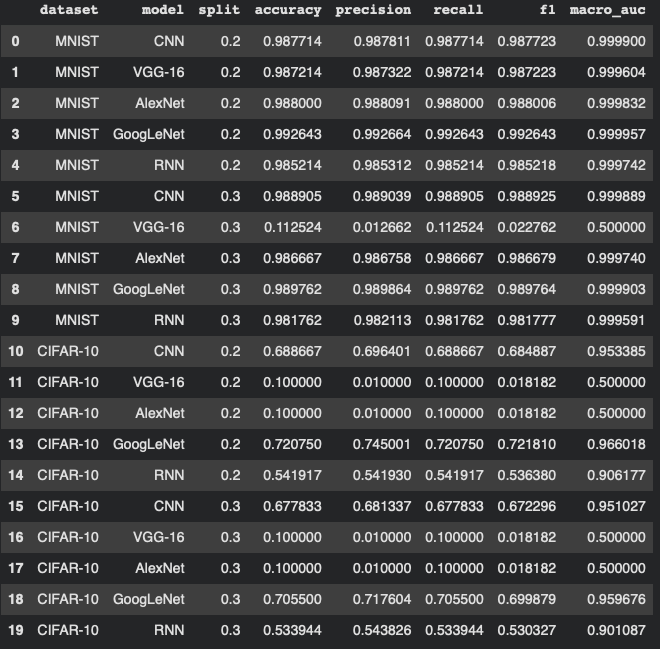

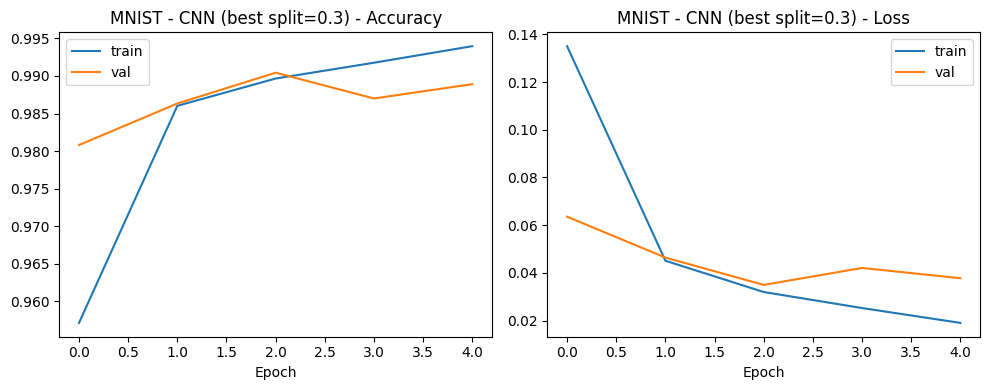

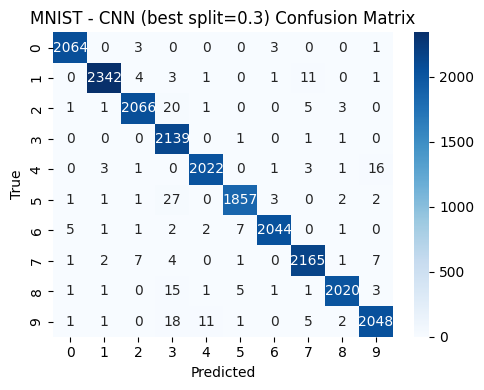

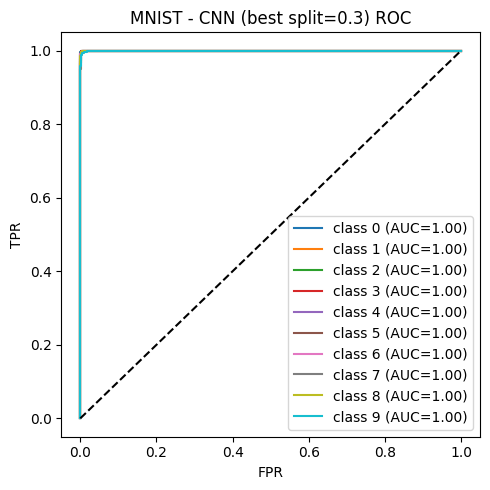

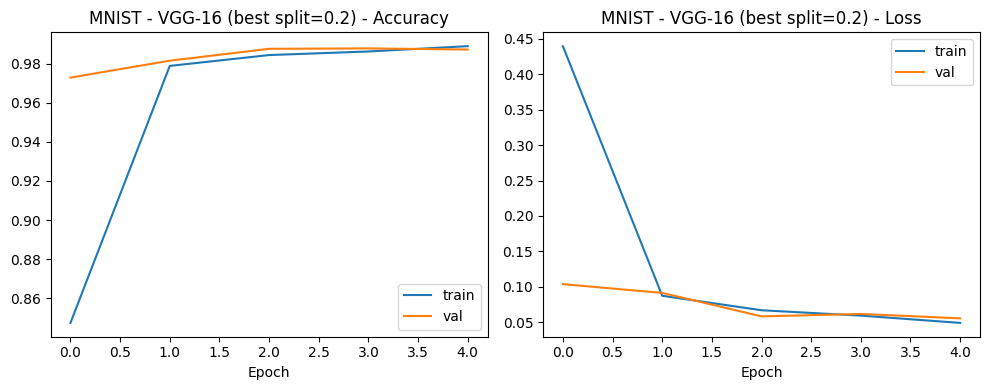

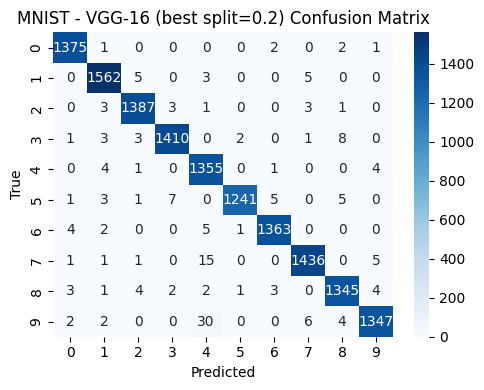

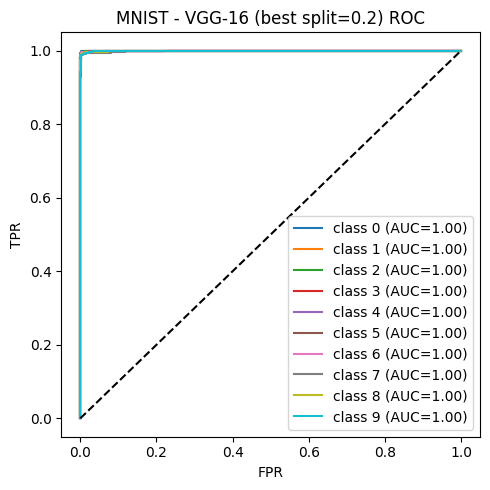

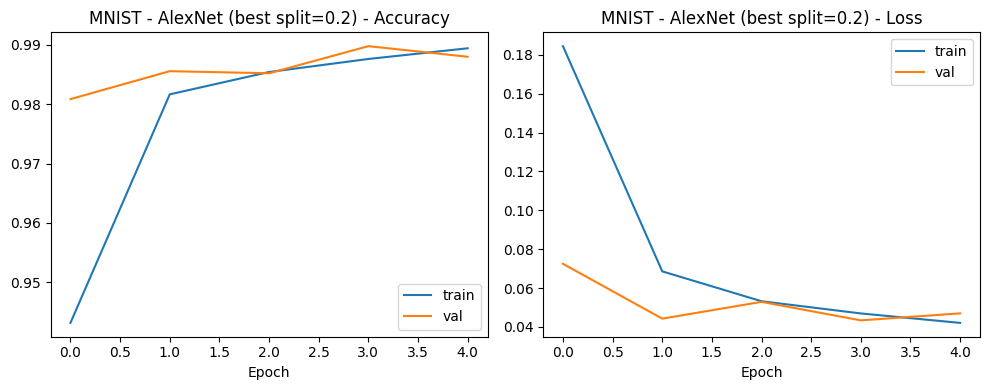

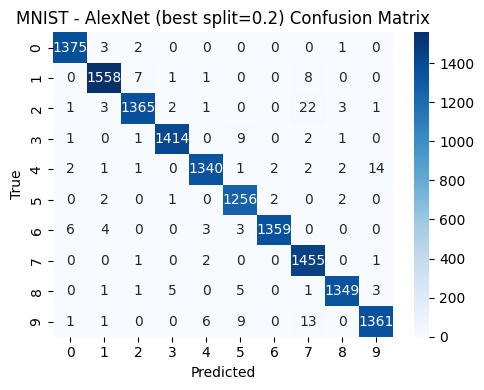

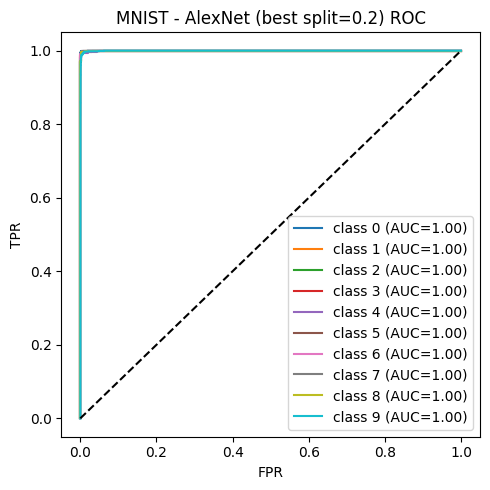

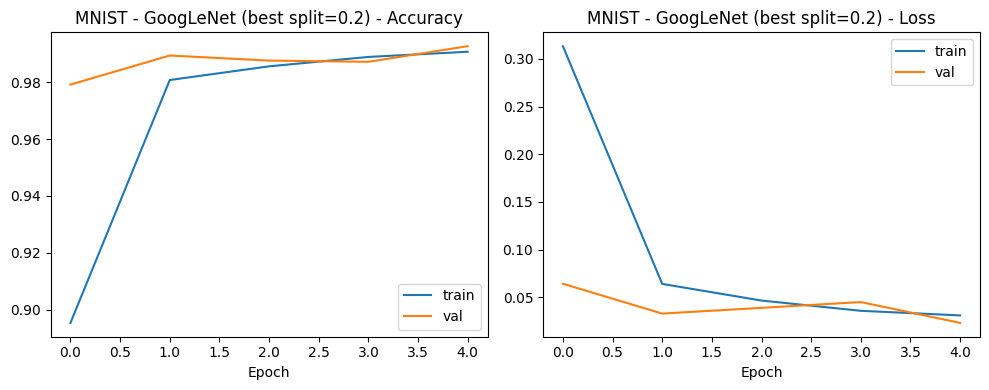

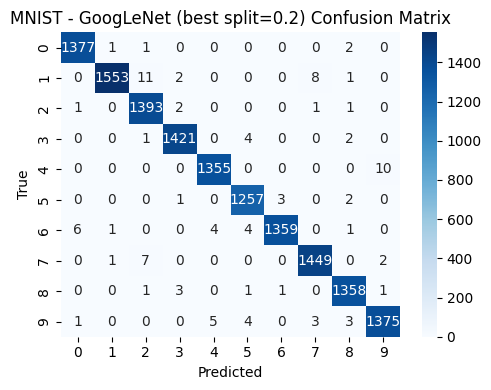

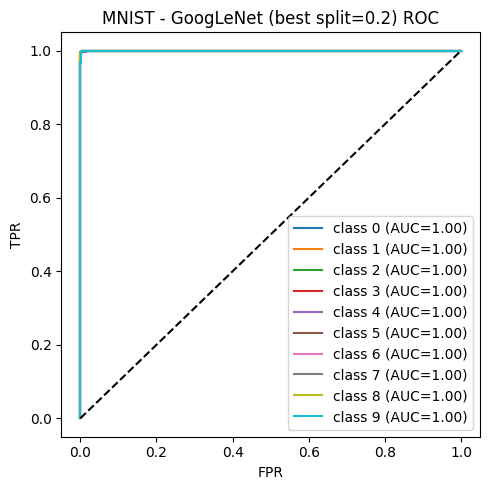

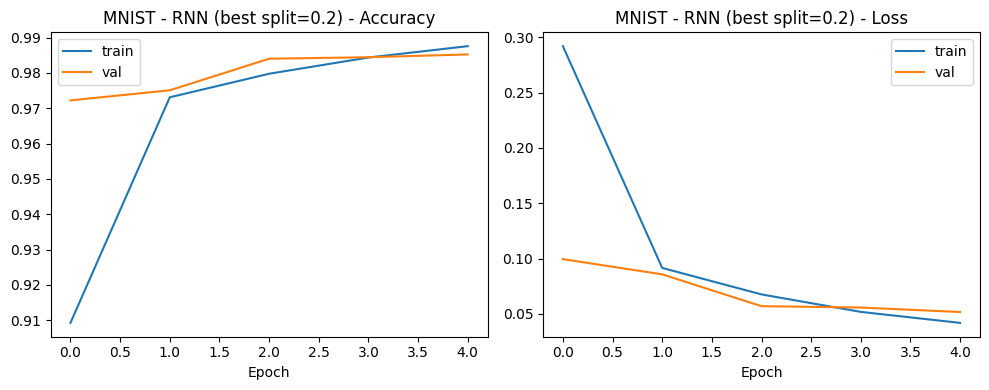

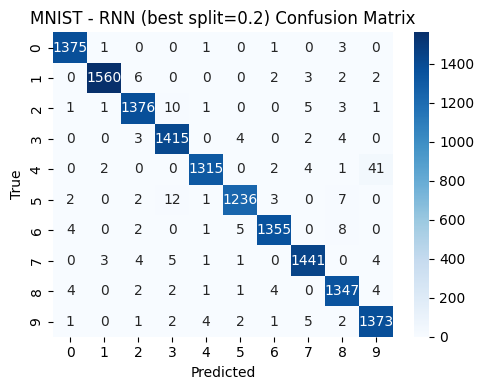

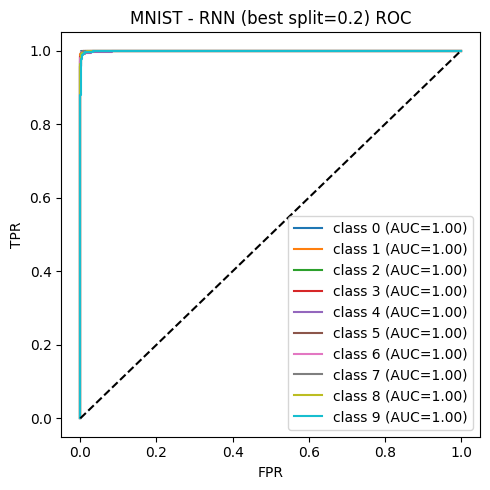

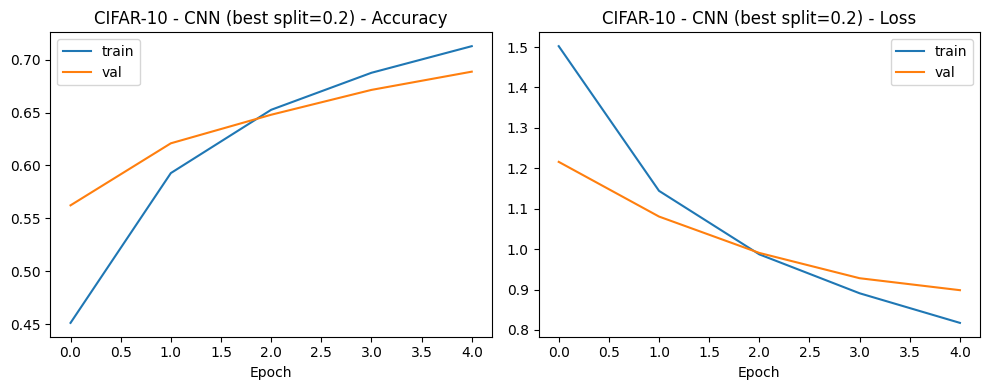

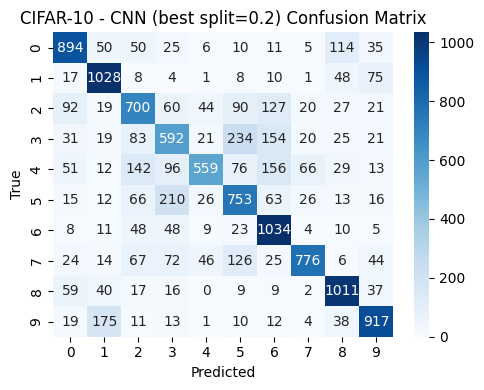

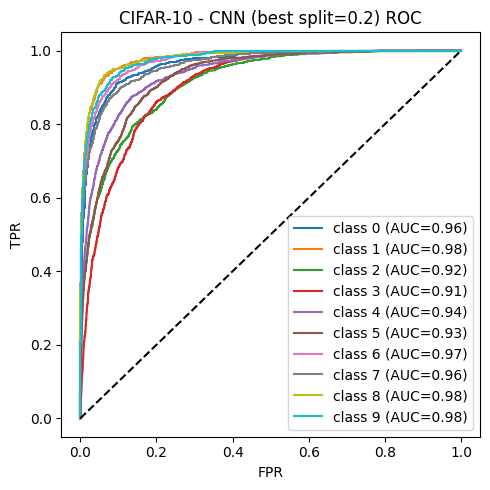

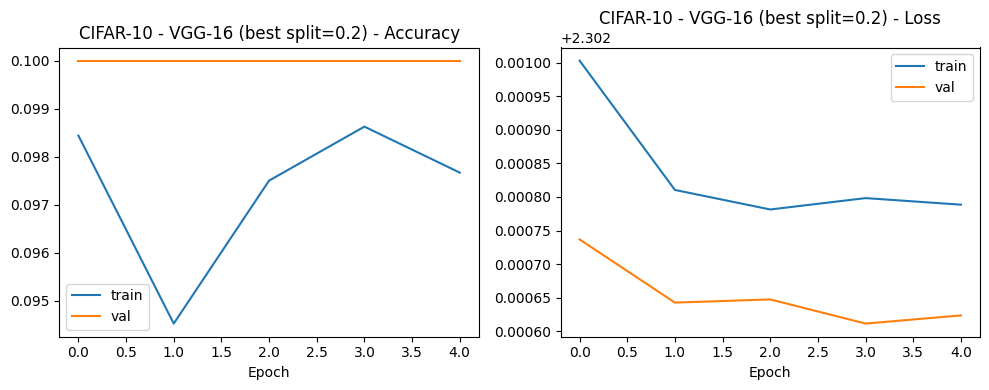

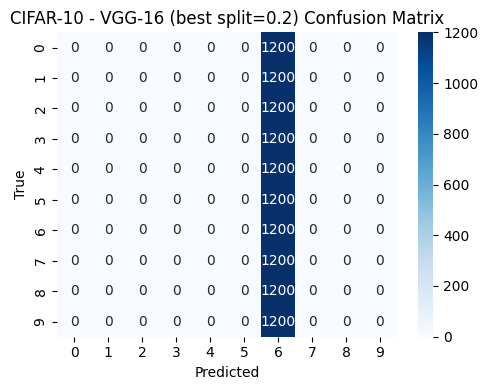

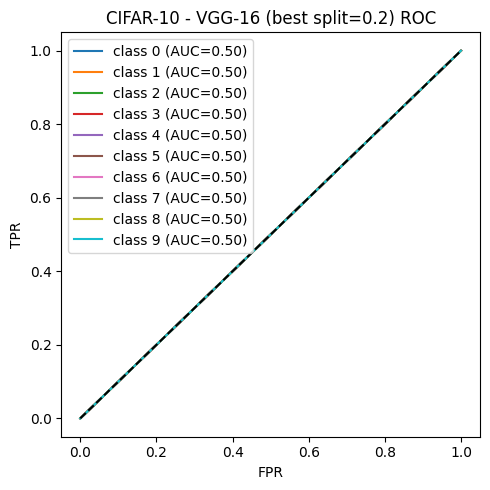

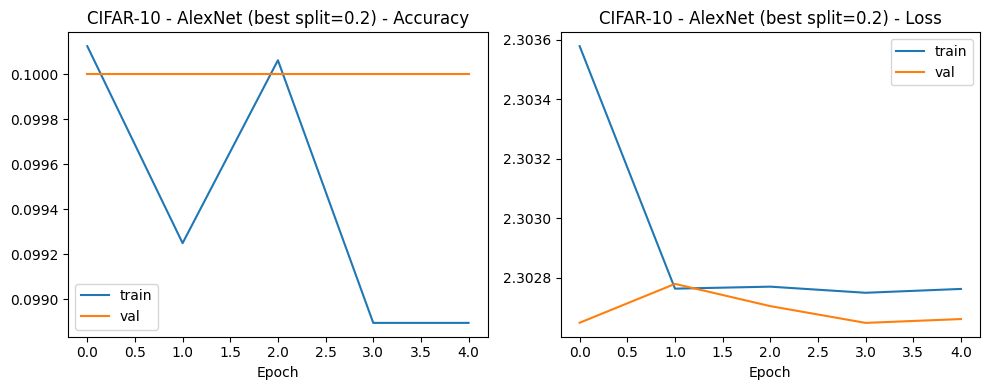

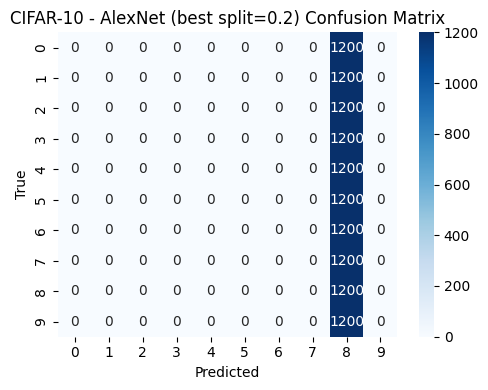

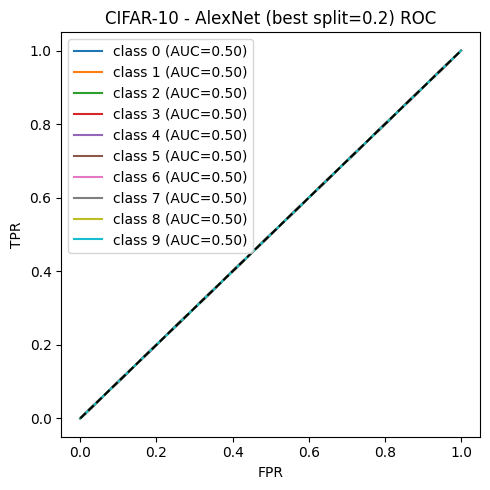

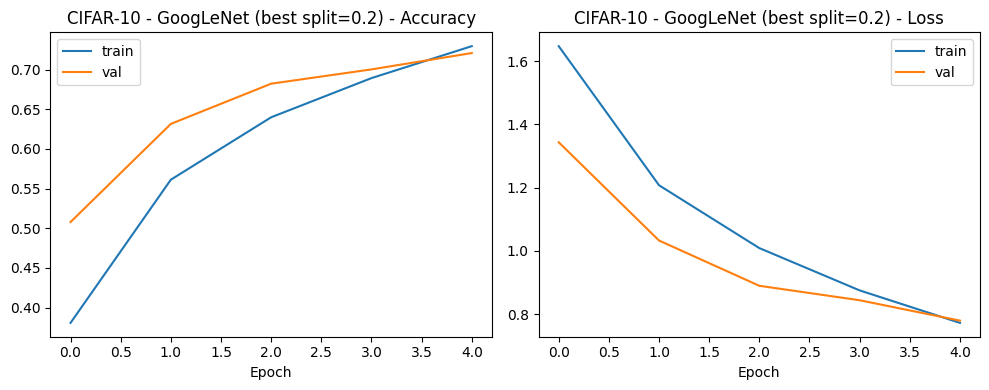

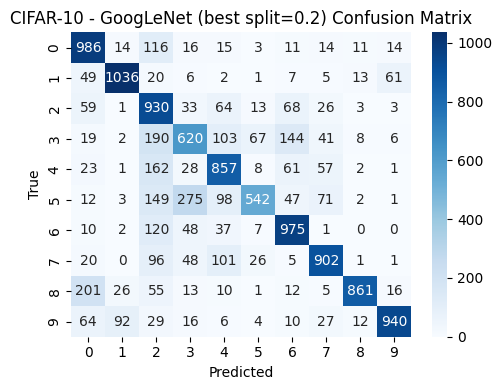

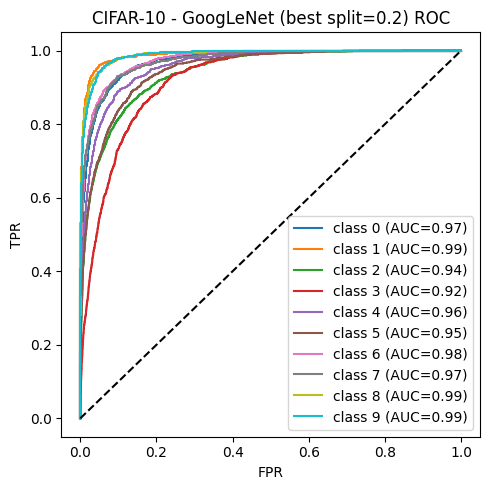

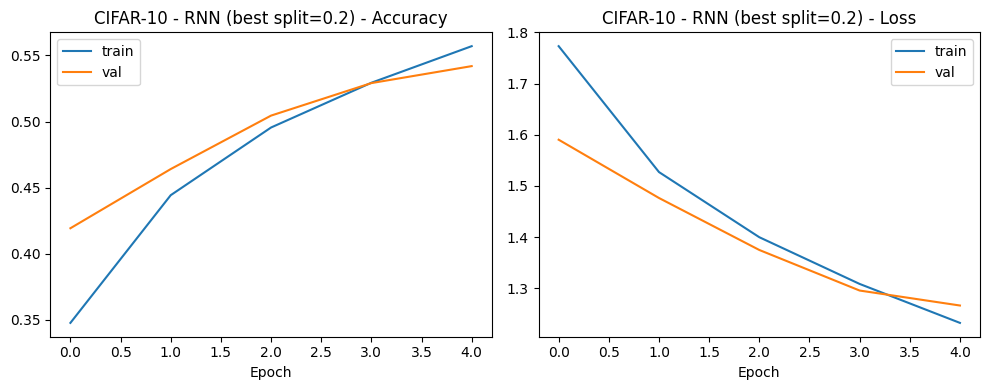

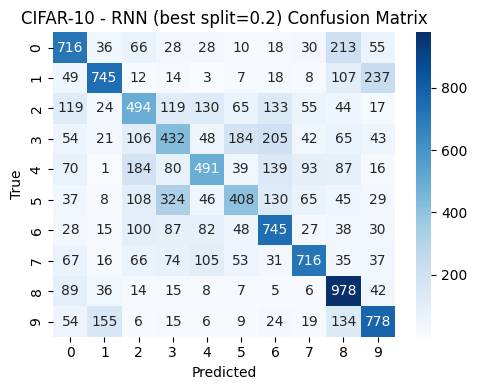

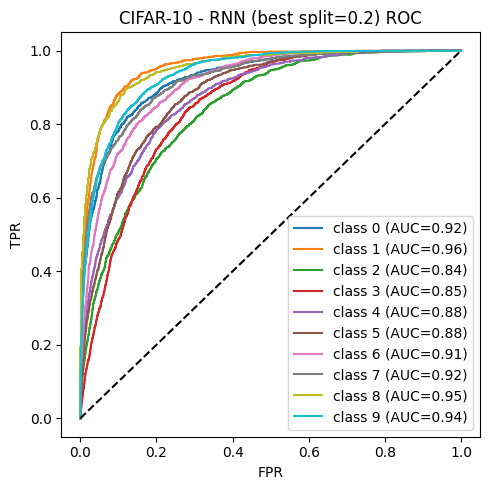

In [ ]:
for (dataset_name, model_name), res in dl_best.items():
    title = f"{dataset_name} - {model_name} (best split={res['split']})"
    plot_training_curves(res["history"], title, f"{dataset_name}_{model_name}_curves.png")
    plot_confusion_heatmap(res["confusion_matrix"], list(range(res["num_classes"])),
                            f"{title} Confusion Matrix", f"{dataset_name}_{model_name}_cm.png")
    plot_roc(res["fpr"], res["tpr"], res["roc_auc"], f"{title} ROC", f"{dataset_name}_{model_name}_roc.png")

### Performance comparison table
Best (highest-accuracy) split per dataset/model, pulled from `dl_comparison`.

In [ ]:
dl_summary = dl_comparison.sort_values("accuracy", ascending=False).groupby(["dataset", "model"]).first().reset_index()
dl_summary

,dataset,model,split,accuracy,precision,recall,f1,macro_auc
0,CIFAR-10,AlexNet,0.2,0.100000,0.010000,0.100000,0.018182,0.500000
1,CIFAR-10,CNN,0.2,0.688667,0.696401,0.688667,0.684887,0.953385
2,CIFAR-10,GoogLeNet,0.2,0.720750,0.745001,0.720750,0.721810,0.966018
3,CIFAR-10,RNN,0.2,0.541917,0.541930,0.541917,0.536380,0.906177
4,CIFAR-10,VGG-16,0.2,0.100000,0.010000,0.100000,0.018182,0.500000
5,MNIST,AlexNet,0.2,0.988000,0.988091,0.988000,0.988006,0.999832
6,MNIST,CNN,0.3,0.988905,0.989039,0.988905,0.988925,0.999889
7,MNIST,GoogLeNet,0.2,0.992643,0.992664,0.992643,0.992643,0.999957
8,MNIST,RNN,0.2,0.985214,0.985312,0.985214,0.985218,0.999742
9,MNIST,VGG-16,0.2,0.987214,0.987322,0.987214,0.987223,0.999604


## Performance Comparison

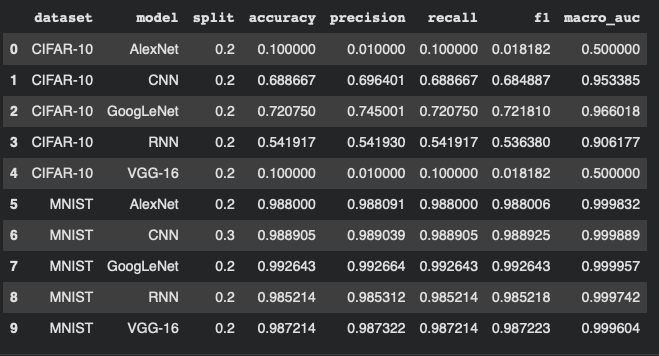

### Discussion
- CNN gives a strong lightweight baseline on both datasets; MNIST typically reaches >=90% accuracy within a handful of epochs, while CIFAR-10 needs more epochs/regularization/augmentation to reach the same bar because of its higher intra-class variability and color channels.
- VGG-16 and GoogLeNet (deeper, with more representational capacity) generally outperform the plain CNN and AlexNet on CIFAR-10 given enough training, at the cost of longer training time and more parameters (VGG-16 in particular).
- The RNN (LSTM over image rows) is the weakest architecture for both datasets since it discards the 2D spatial structure that convolutions exploit; it mainly serves as a sanity-check baseline here.